# Supervised and unsupervised learning!

## 🗂️ Project structure

1. Following the task description, you'll find a set of formal requirements that your solution must meet.
2. The primary measure of your success is the **test** performance of your model, as specified in each problem.
3. After completing each task, you must answer a series of questions, marked with ❓, to demonstrate your understanding of the techniques used.
4. You may create as many cells as needed, but the final results should be kept in a short and simple cell.

## 📝 Submission guidelines

- For each problem, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.
- Submit this notebook (**problem.ipynb**) to Canvas. Deliver the notebook such that outputs are saved, ideally *restart* the kernel followed by *run all*.
- Use Kaggle to check your cluster assignments while you work. More details are in the problem description.
- Include your final **submission.csv** in the Canvas delivery, together with this notebook.

Good luck!

---


# 🎯 Problem 1: Training Neural Networks

### ❗️ The problem

Train neural networks for:
- A binary classification problem
- A non-linear regression problem

To reach the target performance, you may want to experiment with optimization techniques such as:
- Full-batch vs. mini-batch training
- Learning-rate scheduling (e.g., cosine annealing)
- Hyperparameter tuning (learning rate, batch size, depth, width)
- Optimizers (e.g., Adam, RMSprop, SGD)
- Activation functions (e.g., sigmoid, tanh, ReLU, GELU)
- Early stopping
- And more!

### 📋 Formal requirements

1. **Implementation**
   - Use Tensorflow/Keras or PyTorch for each problem (for Keras, you may find these guides useful: [Sequential model](https://keras.io/guides/sequential_model/) and [Training with built-in methods](https://keras.io/guides/training_with_built_in_methods/))
   - Try **at least three** of the techniques listed above.
   - Results must be **reproducible**: rerunning the notebook should yield the same metrics (fix random seeds).

2. **Performance**
   - **Classification**: at least **90% accuracy on the test set**.
   - **Regression**: at most **0.25 RMSE** on the test inputs, scored by `plot_complex_fit`.

3. **Discussion**
   - How did you ensure reproducibility?
   - Visualize/explain the network architecture for both classification and regression (e.g., block diagram, parameter counts, activation functions, etc.).
   - Plot the classification **decision boundary** with `plot_decision_boundary` from `utils`. Would the model generalize to larger feature values?
   - Plot train and held-out loss vs. epoch for classification and for regression. What do these curves tell you? Are the final values a good way to judge the model performance?
   - Which optimization techniques did you try? What worked and what did not?


In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from utils import plot_complex_fit, plot_decision_boundary, complex_function
import keras 
from keras import ops
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split 
from keras.utils import plot_model


# Any other imports you need

## Binary classification


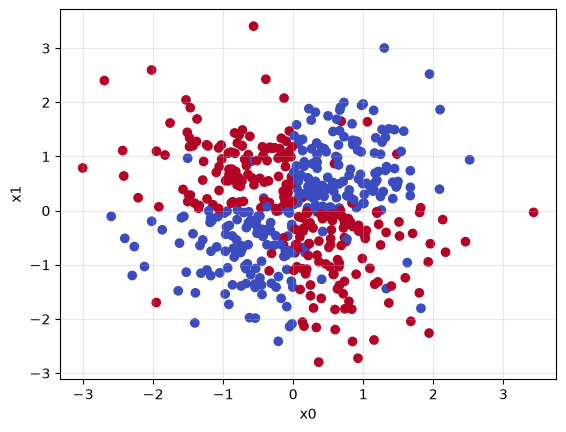

In [2]:
# This is our problem... It's basically XOR, but with continuous values (and a lot of noise!)
data = pd.read_csv("classification_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]

train, val = train_test_split(train, test_size=.3, random_state=42)
X_train = train.drop(['y','split'],axis=1)
y_train = train['y']

X_val = val.drop(['y','split'],axis=1)
y_val = val['y']


X_test = test.drop(['y','split'],axis=1)
y_test = test['y']

X_train_tensor = tf.constant(X_train.values,dtype=tf.float32)
y_train_tensor = tf.constant(y_train.values,dtype=tf.float32)



plt.scatter(test["x0"], test["x1"], c=test["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.grid(True, alpha=0.3)
plt.show()




16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
lr_schedule 0.918


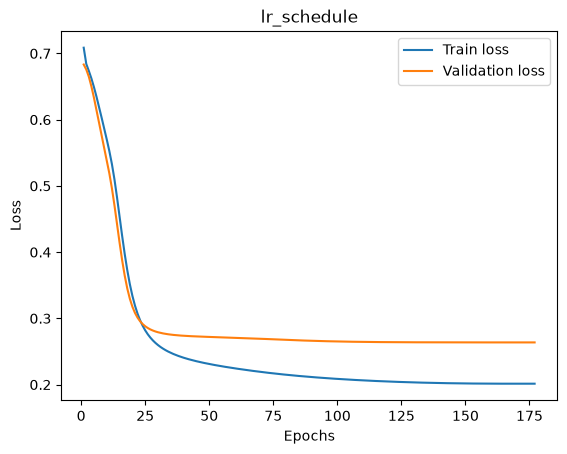

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
SGD 0.766


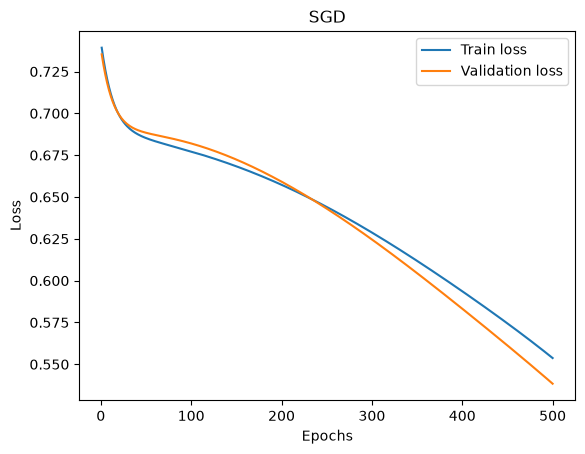

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
SGD_momentum 0.9


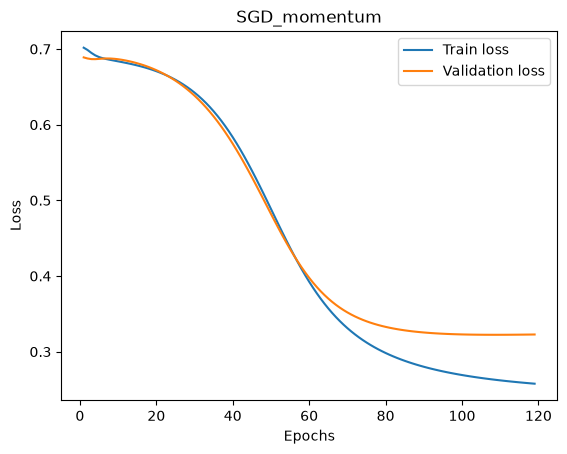

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Adam 0.9


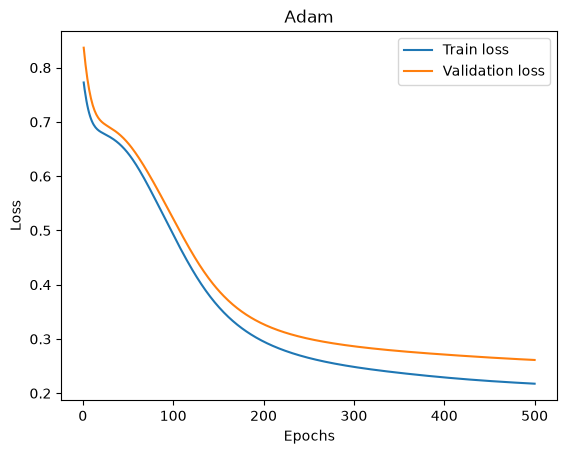

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
RMSprop 0.47


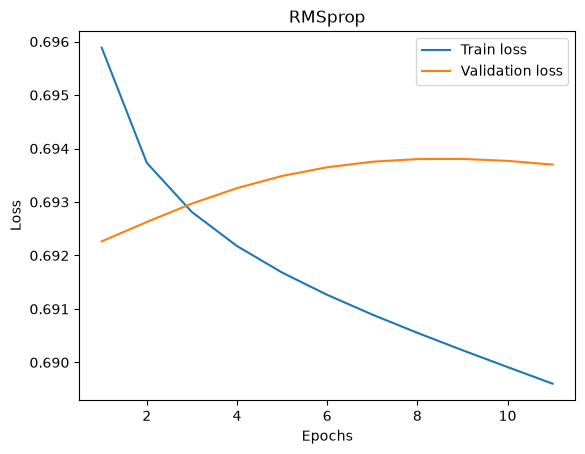

In [129]:
# ====================================
# YOUR CODE GOES HERE
# ====================================
keras.utils.set_random_seed(42)
def create_model():
    model = Sequential() 
    model.add(keras.Input(shape=(2,)))
    model.add(Dense(8, activation="tanh", name = "layer1"))
    model.add(Dense(8,activation="tanh",name="layer2"))
    model.add(Dense(1,activation="sigmoid", name="output"))
    return model 
early_stop = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience=10,
    restore_best_weights=True
)

optimizers={
    'lr_schedule':keras.optimizers.SGD(learning_rate=keras.optimizers.schedules.CosineDecay(initial_learning_rate=.5,decay_steps=1000)),
    'SGD': keras.optimizers.SGD(learning_rate=.01),
    'SGD_momentum' :keras.optimizers.SGD(learning_rate=.01, momentum=.9),
    'Adam': keras.optimizers.Adam(learning_rate=.001),
    'RMSprop' : keras.optimizers.RMSprop(learning_rate=.001)
}
for name, optimizer in optimizers.items():
    model = create_model()
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    history = model.fit(X_train,y_train,batch_size=64,epochs=500,validation_data=(X_val, y_val),verbose=0,callbacks=[early_stop])
  
    
    y_pred = (model.predict(X_test)>=.5).astype(int).ravel()
    accuracy = np.mean(y_pred == y_test.to_numpy())
    print(name, accuracy)
    train_losses = history.history["loss"]
    val_losses = history.history["val_loss"]
    epochs = np.arange(1, len(train_losses)+1)
    plt.plot(epochs, train_losses, label="Train loss")
    plt.plot(epochs, val_losses, label="Validation loss")
    plt.title(f'{name}')
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()



Adam så bra ut, la oss fortsette med den

In [134]:
learning_rates = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
seeds = [1, 2, 3, 4, 5]

results = {}

for lr in learning_rates:

    scores = []

    for seed in seeds:

        keras.utils.set_random_seed(seed)

        model = create_model()

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=lr),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        model.fit(
            X_train,
            y_train,
            batch_size=64,
            epochs=1000,
            validation_data=(X_val, y_val),
            callbacks=[early_stop],
            verbose=0
        )

        val_loss, val_acc = model.evaluate(
            X_val, y_val, verbose=0
        )

        scores.append(val_loss)

    results[lr] = (np.mean(scores), np.std(scores))

for lr, (mean_loss, std_loss) in results.items():
    print(
        f"{lr}: {mean_loss:.4f} ± {std_loss:.4f}"
    )

0.0001: 0.5042 ± 0.0328
0.0003: 0.3025 ± 0.0115
0.001: 0.2813 ± 0.0235
0.003: 0.2795 ± 0.0239
0.01: 0.2911 ± 0.0216


In [157]:
batch_sizes = [16, 32, 64, 128, len(X_train)]

for batch_size in batch_sizes:
    losses = []

    for seed in [1, 2, 3, 4, 5]:
        keras.utils.set_random_seed(seed)

        model = create_model()

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.003),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        history = model.fit(
            X_train,
            y_train,
            batch_size=batch_size,
            epochs=1000,
            validation_data=(X_val, y_val),
            callbacks=[early_stop],
            verbose=0
        )

        val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)

        losses.append(val_loss)

    print(
        batch_size,
        np.mean(losses),
        np.std(losses)
    )

16 0.28629260063171386 0.02113398549975328
32 0.2812244951725006 0.02184754436446469
64 0.2794745028018951 0.023890756188270496
128 0.2841073751449585 0.02255640310121819
350 0.4404871940612793 0.20083791388749822


Tenker vi holder oss til batch size 64 i batch size jeg. Vi kan jo også sjekke om den blir bedre av et "enklere" hidden layer nettverk 

Epoch 1/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 0.5229 - loss: 0.7233 - val_accuracy: 0.5067 - val_loss: 0.6977
Epoch 2/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5229 - loss: 0.7045 - val_accuracy: 0.5000 - val_loss: 0.6886
Epoch 3/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5286 - loss: 0.6935 - val_accuracy: 0.5133 - val_loss: 0.6850
Epoch 4/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5429 - loss: 0.6876 - val_accuracy: 0.5333 - val_loss: 0.6843
Epoch 5/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5543 - loss: 0.6846 - val_accuracy: 0.5667 - val_loss: 0.6843
Epoch 6/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5457 - loss: 0.6826 - val_accuracy: 0.5533 - val_loss: 0.6835
Epoch 7/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5457 - loss: 0.6805 - val_accuracy: 0.5533 - val_loss: 0.6818
Epoch 8/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5457 - loss: 0.6781 - val_accuracy: 0.5533 - 

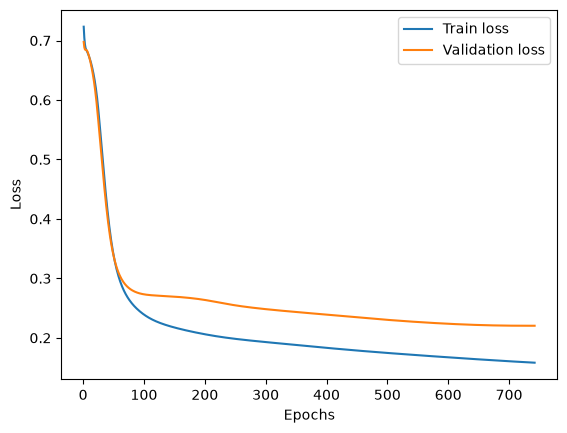

In [ ]:
keras.utils.set_random_seed(42)


model = Sequential() 
model.add(keras.Input(shape=(2,)))
model.add(Dense(8, activation="tanh", name = "layer1"))
model.add(Dense(8,activation="tanh",name="layer2"))
model.add(Dense(1,activation="sigmoid", name="output"))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=1000,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    
)
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs = np.arange(1, len(train_losses)+1)
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()




Epoch 1/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.4771 - loss: 0.7445 - val_accuracy: 0.5200 - val_loss: 0.7258
Epoch 2/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4800 - loss: 0.7312 - val_accuracy: 0.5133 - val_loss: 0.7161
Epoch 3/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4829 - loss: 0.7200 - val_accuracy: 0.5067 - val_loss: 0.7083
Epoch 4/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4771 - loss: 0.7107 - val_accuracy: 0.5200 - val_loss: 0.7023
Epoch 5/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4686 - loss: 0.7032 - val_accuracy: 0.5200 - val_loss: 0.6980
Epoch 6/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4686 - loss: 0.6974 - val_accuracy: 0.5200 - val_loss: 0.6949
Epoch 7/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4771 - loss: 0.6930 - val_accuracy: 0.4933 - val_loss: 0.6928
Epoch 8/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4486 - loss: 0.6897 - val_accuracy: 0.4400 - v

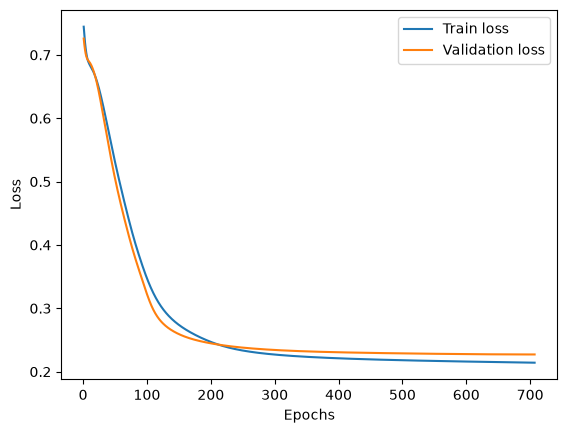

In [167]:
keras.utils.set_random_seed(42)


model = Sequential() 
model.add(keras.Input(shape=(2,)))
model.add(Dense(4, activation="tanh", name = "layer1"))
model.add(Dense(4,activation="tanh",name="layer2"))
model.add(Dense(1,activation="sigmoid", name="output"))

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=1000,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    
)
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs = np.arange(1, len(train_losses)+1)
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()




In [170]:
architectures = [
    (2,2),
    (2,4),
    (4,2),
    (4,4),
    (4,8),
    (8,4),
    (8,8)
]

seeds = [1,2,3,4,5]

results = {}

for architecture in architectures:

    losses = []
    accuracies = []

    for seed in seeds:

        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)

        model = Sequential([
            keras.Input(shape=(2,)),
            Dense(architecture[0], activation="tanh"),
            Dense(architecture[1], activation="tanh"),
            Dense(1, activation="sigmoid")
        ])

        model.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=0.003
            ),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        model.fit(
            X_train,
            y_train,
            batch_size=64,
            epochs=1000,
            validation_data=(X_val, y_val),
            callbacks=[early_stop],
            verbose=0
        )

        val_loss, val_acc = model.evaluate(
            X_val,
            y_val,
            verbose=0
        )

        losses.append(val_loss)
        accuracies.append(val_acc)

        print(f"Done with {architecture}: seed {seed}")

    results[architecture] = {
        "loss_mean": np.mean(losses),
        "loss_std": np.std(losses),
        "acc_mean": np.mean(accuracies),
        "acc_std": np.std(accuracies)
    }

for architecture, result in results.items():
    print(
        architecture,
        f"loss: {result['loss_mean']:.4f} ± {result['loss_std']:.4f}",
        f"accuracy: {result['acc_mean']:.4f} ± {result['acc_std']:.4f}"
    )


Done with (2, 2): seed 1
Done with (2, 2): seed 2
Done with (2, 2): seed 3
Done with (2, 2): seed 4
Done with (2, 2): seed 5
Done with (2, 4): seed 1
Done with (2, 4): seed 2
Done with (2, 4): seed 3
Done with (2, 4): seed 4
Done with (2, 4): seed 5
Done with (4, 2): seed 1
Done with (4, 2): seed 2
Done with (4, 2): seed 3
Done with (4, 2): seed 4
Done with (4, 2): seed 5
Done with (4, 4): seed 1
Done with (4, 4): seed 2
Done with (4, 4): seed 3
Done with (4, 4): seed 4
Done with (4, 4): seed 5
Done with (4, 8): seed 1
Done with (4, 8): seed 2
Done with (4, 8): seed 3
Done with (4, 8): seed 4
Done with (4, 8): seed 5
Done with (8, 4): seed 1
Done with (8, 4): seed 2
Done with (8, 4): seed 3
Done with (8, 4): seed 4
Done with (8, 4): seed 5
Done with (8, 8): seed 1
Done with (8, 8): seed 2
Done with (8, 8): seed 3
Done with (8, 8): seed 4
Done with (8, 8): seed 5
(2, 2) loss: 0.5263 ± 0.1712 accuracy: 0.6920 ± 0.1289
(2, 4) loss: 0.4682 ± 0.2146 accuracy: 0.6987 ± 0.2337
(4, 2) loss: 0

8x8 modellen er best åpenbart. La oss bruke den. Den er jo egentlig grei nok nå, trenger ikke gjøre noe særlig mer.

### ❓ Visualize the network architecture for both classification and regression.


Epoch 1/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 182ms/step - accuracy: 0.5229 - loss: 0.7233 - val_accuracy: 0.5067 - val_loss: 0.6977
Epoch 2/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5229 - loss: 0.7045 - val_accuracy: 0.5000 - val_loss: 0.6886
Epoch 3/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5286 - loss: 0.6935 - val_accuracy: 0.5133 - val_loss: 0.6850
Epoch 4/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5429 - loss: 0.6876 - val_accuracy: 0.5333 - val_loss: 0.6843
Epoch 5/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5543 - loss: 0.6846 - val_accuracy: 0.5667 - val_loss: 0.6843
Epoch 6/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5457 - loss: 0.6826 - val_accuracy: 0.5533 - val_loss: 0.6835
Epoch 7/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5457 - loss: 0.6805 - val_accuracy: 0.5533 - val_loss: 0.6818
Epoch 8/1000
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5457 - loss: 0.6781 - val_accuracy: 0.5533 - 

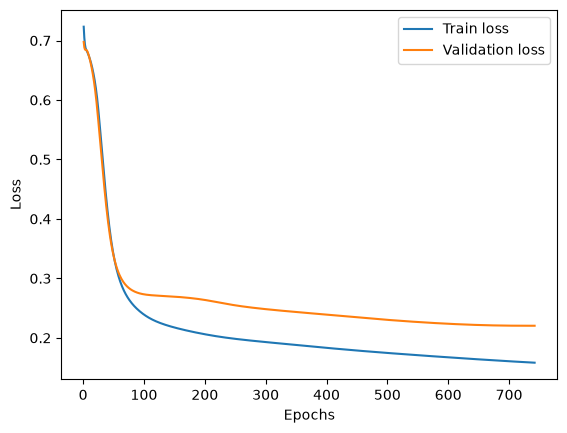

In [3]:
from keras.utils import plot_model
keras.utils.set_random_seed(42)


model_final = Sequential() 
model_final.add(keras.Input(shape=(2,)))
model_final.add(Dense(8, activation="tanh", name = "layer1"))
model_final.add(Dense(8,activation="tanh",name="layer2"))
model_final.add(Dense(1,activation="sigmoid", name="output"))

model_final.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model_final.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=1000,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    
)
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs = np.arange(1, len(train_losses)+1)
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()





Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 317 (1.24 KB)

 Trainable params: 105 (420.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 212 (852.00 B)

None
You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
0.912


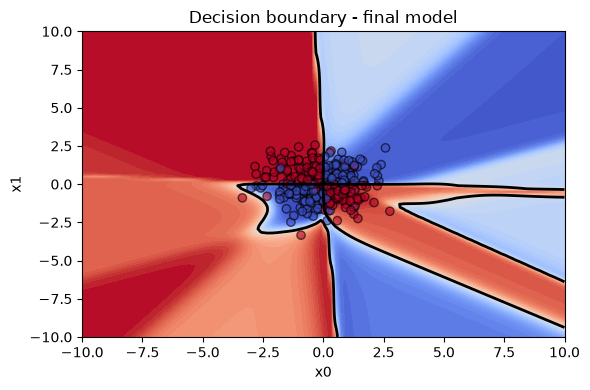

In [6]:
print(model_final.summary())
plot_model(
    model_final,
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True
)

y_pred = (model_final.predict(X_test)>=.5).astype(int).ravel()
accuracy = np.mean(y_pred == y_test.to_numpy())

print(accuracy)

fig, ax = plot_decision_boundary(
    predict=lambda X: model_final.predict(X, verbose=0),
    threshold=0.5,
    points=X_train,
    labels=y_train,
    xlim=(-10,10),
    ylim=(-10,10)
)

ax.set_title(f"Decision boundary - final model")
plt.show()


Kanskje en smule overfitting her, spesielt rundt negative x1 verdier. Kan bli problematisk for større verdier. 

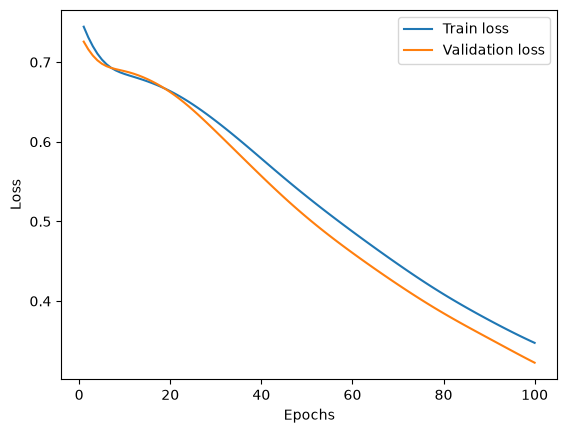

In [7]:
from keras.utils import plot_model
from keras import regularizers
keras.utils.set_random_seed(42)


model_final = Sequential() 
model_final.add(keras.Input(shape=(2,)))
model_final.add(Dense(4, activation="tanh"))
model_final.add(Dense(4,activation="tanh",name="layer2"))
model_final.add(Dense(1,activation="sigmoid", name="output"))

model_final.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model_final.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=100,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose = 0
    
)
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
epochs = np.arange(1, len(train_losses)+1)
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()





16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
0.862


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113 (456.00 B)

 Trainable params: 37 (148.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 76 (308.00 B)

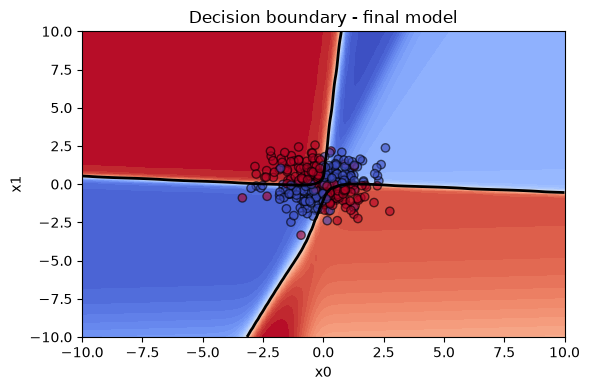

In [9]:
y_pred = (model_final.predict(X_test)>=.5).astype(int).ravel()
accuracy = np.mean(y_pred == y_test.to_numpy())

print(accuracy)
model_final.summary()
fig, ax = plot_decision_boundary(
    predict=lambda X: model_final.predict(X, verbose=0),
    threshold=0.5,
    points=X_train,
    labels=y_train,
    xlim=(-10,10),
    ylim=(-10,10)
)

ax.set_title(f"Decision boundary - final model")
plt.show()

### ❓ Plot the classification decision boundary. Would the model generalize to larger feature values? 
I noen retninger i hvert fall. Kanskje litt overfitted. Så kanskje 4x4 var bedre afterall. 

## Regression


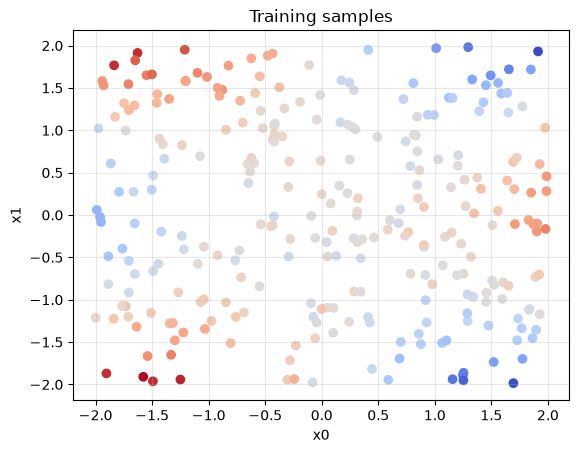

In [17]:
# We have a new dataset now. This time, the target is continuous.
# Test rows have no y. For a validation split, hold out part of train.

import itertools 
import numpy as np 
data = pd.read_csv("regression_data.csv")
train = data[data["split"] == "train"]
test = data[data["split"] == "test"]
train, val = train_test_split(train, test_size=.3, random_state=42)
X_train = train.drop(['y','split'],axis=1)
y_train = train['y']

X_val = val.drop(['y','split'],axis=1)
y_val = val['y']
plt.scatter(train["x0"], train["x1"], c=train["y"], cmap="coolwarm")
plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Training samples")
plt.grid(True, alpha=0.3)
plt.show()

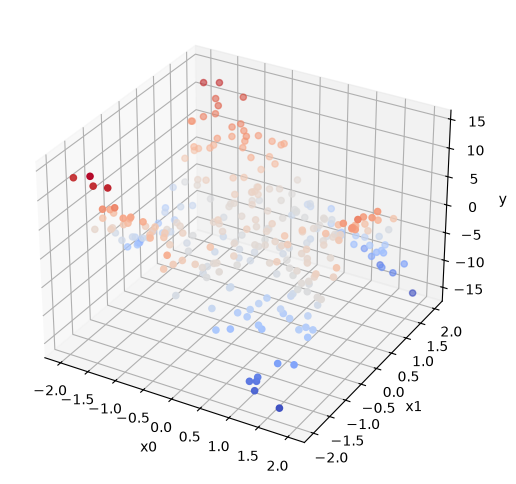

In [9]:
# Hmmm, maybe 3d is better
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train["x0"], train["x1"], train["y"], c=train["y"], cmap="coolwarm")
ax.set_xlabel("x0")
ax.set_ylabel("x1")
ax.set_zlabel("y")
plt.show()

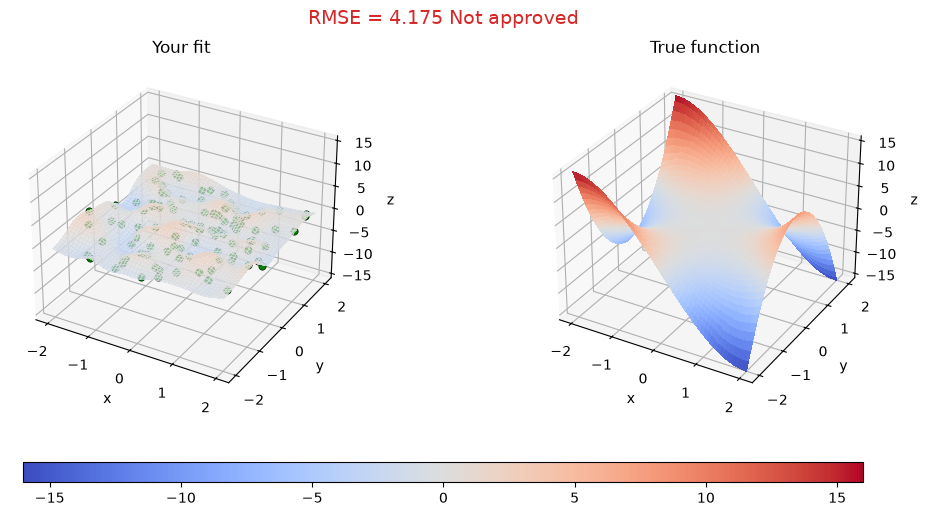

In [8]:
# plot_complex_fit compares your predictions to the true surface and prints RMSE
# plot_complex_fit has no noise, so expect a lower RMSE here
# The test rows have no y, so this is how you score them.
test_xy = test[["x0", "x1"]].values
y_pred_demo = np.random.randn(len(test))

plot_complex_fit(test_xy, y_pred_demo)
plt.show()

# Random predictions fail the 0.25 RMSE threshold.

In [30]:

import numpy as np
import pandas as pd
import keras
import time

def create_model(architecture, activation):
    model = keras.Sequential([
        keras.Input(shape=(X_train.shape[1],)),
        *[
            keras.layers.Dense(n, activation=activation)
            for n in architecture
        ],
        keras.layers.Dense(1)
    ])
    return model

X_val_np = np.asarray(X_val)
true_y = complex_function(X_val_np[:, 0], X_val_np[:, 1])


def train_and_evaluate(config, seed=42, epochs=400, patience=25):

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    model = create_model(
        config["architecture"],
        config["activation"]
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=config["lr"]
        ),
        loss="mse"
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=patience,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        batch_size=config["batch_size"],
        epochs=epochs,
        callbacks=[early_stop],
        verbose=0
    )

    pred = model.predict(X_val, verbose=0).ravel()

    true_rmse = np.sqrt(np.mean((pred - true_y)**2))
    val_rmse = np.sqrt(
        np.mean((pred - np.asarray(y_val).ravel())**2)
    )

    return true_rmse, val_rmse, len(history.history["loss"])


# Startkonfigurasjon
best_config = {
    "architecture": (64, 64),
    "activation": "relu",
    "lr": 0.001,
    "batch_size": 64
}

search_space = [
    ("lr", [0.001, 0.003, 0.01]),
    ("activation", ["relu", "tanh", "gelu"]),
    ("architecture", [(32,32), (64,64), (128,128)]),
    ("batch_size", [32, 64])
]

results = []
start = time.perf_counter()

for parameter, values in search_space:

    print(f"\n--- Optimizing {parameter} ---")
    stage_results = []

    for value in values:

        config = best_config.copy()
        config[parameter] = value

        rmse, val_rmse, n_epochs = train_and_evaluate(config)

        result = {
            **config,
            "true_rmse": rmse,
            "val_rmse": val_rmse,
            "epochs": n_epochs
        }

        results.append(result)
        stage_results.append(result)

        print(
            f"{parameter}={value}: "
            f"RMSE={rmse:.4f}, "
            f"epochs={n_epochs}"
        )

    # Velg beste verdi for denne hyperparameteren
    best = min(stage_results, key=lambda x: x["true_rmse"])
    best_config[parameter] = best[parameter]

    print(f"BEST {parameter}: {best[parameter]}")
    print(f"RMSE: {best['true_rmse']:.4f}")

print("\nFINAL CONFIGURATION:")
print(best_config)

print(f"\nTime: {(time.perf_counter()-start)/60:.1f} min")

results_df = pd.DataFrame(results)
display(results_df)



--- Optimizing lr ---
lr=0.001: RMSE=0.5275, epochs=400
lr=0.003: RMSE=0.5402, epochs=160
lr=0.01: RMSE=0.5225, epochs=77
BEST lr: 0.01
RMSE: 0.5225

--- Optimizing activation ---
activation=relu: RMSE=0.5225, epochs=77
activation=tanh: RMSE=0.5697, epochs=147
activation=gelu: RMSE=0.3128, epochs=72
BEST activation: gelu
RMSE: 0.3128

--- Optimizing architecture ---
architecture=(32, 32): RMSE=0.3779, epochs=92
architecture=(64, 64): RMSE=0.3128, epochs=72
architecture=(128, 128): RMSE=0.3516, epochs=76
BEST architecture: (64, 64)
RMSE: 0.3128

--- Optimizing batch_size ---
batch_size=32: RMSE=0.3264, epochs=70
batch_size=64: RMSE=0.3128, epochs=72
BEST batch_size: 64
RMSE: 0.3128

FINAL CONFIGURATION:
{'architecture': (64, 64), 'activation': 'gelu', 'lr': 0.01, 'batch_size': 64}

Time: 1.8 min


,architecture,activation,lr,batch_size,true_rmse,val_rmse,epochs
0,"(64, 64)",relu,0.001,64,0.527545,1.209583,400
1,"(64, 64)",relu,0.003,64,0.540226,1.215160,160
2,"(64, 64)",relu,0.010,64,0.522520,1.196486,77
3,"(64, 64)",relu,0.010,64,0.522520,1.196486,77
4,"(64, 64)",tanh,0.010,64,0.569714,1.193294,147
5,"(64, 64)",gelu,0.010,64,0.312836,1.101139,72
6,"(32, 32)",gelu,0.010,64,0.377869,1.112184,92
7,"(64, 64)",gelu,0.010,64,0.312836,1.101139,72
8,"(128, 128)",gelu,0.010,64,0.351607,1.113664,76
9,"(64, 64)",gelu,0.010,32,0.326386,1.113929,70


In [31]:
seeds = [1, 2, 3]
rmses = []

for seed in seeds:
    rmse, val_rmse, epochs = train_and_evaluate(
        best_config,
        seed=seed,
        epochs=1000,
        patience=50
    )

    rmses.append(rmse)
    print(f"Seed {seed}: RMSE = {rmse:.4f}")

print(
    f"\nMean RMSE: {np.mean(rmses):.4f}"
    f" ± {np.std(rmses):.4f}"
)

Seed 1: RMSE = 0.3276
Seed 2: RMSE = 0.3226
Seed 3: RMSE = 0.3067

Mean RMSE: 0.3190 ± 0.0089


deilig, må dra den hakket lengre ned bare. Sweepe litt rundt et par verdier og standarisering gjør kanskje susen :D


In [42]:
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Dense

x_scaler = StandardScaler()

X_train_s = x_scaler.fit_transform(X_train).astype("float32")
X_val_s = x_scaler.transform(X_val).astype("float32")


# Standardiser y
y_scaler = StandardScaler()
y_train_s = y_scaler.fit_transform(
    np.asarray(y_train).reshape(-1, 1)
).astype("float32")

y_val_s = y_scaler.transform(
    np.asarray(y_val).reshape(-1, 1)
).astype("float32")

# Fasit på valideringspunktene i original skala
X_val_np = np.asarray(X_val)

true_y = complex_function(
    X_val_np[:, 0],
    X_val_np[:, 1]
)

architectures = [
    (64, 64),
    (128, 64),
    (128, 128)
]

learning_rates = [
    3e-4,
    1e-3,
    3e-3
]

seeds = [1, 2]

results = []



def create_model_gelu(architecture):
    model = Sequential()
    model.add(keras.Input(shape=(X_train_s.shape[1],)))

    for n in architecture:
        model.add(Dense(n, activation="gelu"))

    model.add(Dense(1))
    return model


def train_model_new(architecture, lr, seed):

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    model = create_model_gelu(architecture)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="mse"
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=40,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_s,
        y_train_s,
        validation_data=(X_val_s, y_val_s),
        epochs=700,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )

    # Prediksjoner på standardisert skala
    pred_s = model.predict(X_val_s, verbose=0)

    # Tilbake til original target-skala
    pred = y_scaler.inverse_transform(pred_s).ravel()

    # RMSE mot sann funksjon
    true_rmse = np.sqrt(np.mean((pred - true_y)**2))

    # RMSE mot observerte targets
    val_rmse = np.sqrt(
        np.mean((pred - np.asarray(y_val).ravel())**2)
    )

    return model, true_rmse, val_rmse, len(history.history["loss"]), history



In [ ]:

combinations = list(itertools.product(
    architectures, learning_rates, seeds
))

total = len(combinations)
start = time.perf_counter()

for i, (architecture, lr, seed) in enumerate(combinations, 1):

    model, true_rmse, val_rmse, epochs = train_model_new(
        architecture, lr, seed
    )

    results.append({
        "architecture": architecture,
        "lr": lr,
        "seed": seed,
        "true_rmse": true_rmse,
        "val_rmse": val_rmse,
        "epochs": epochs
    })

    elapsed = time.perf_counter() - start
    eta = elapsed / i * (total - i)

    print(
        f"[{i}/{total}] "
        f"arch={architecture}, lr={lr}, seed={seed} | "
        f"RMSE={true_rmse:.4f} | "
        f"epochs={epochs} | "
        f"ETA={eta/60:.1f} min",
        flush=True
    )

results_df = pd.DataFrame(results)

summary = (
    results_df
    .groupby(["architecture", "lr"])
    .agg(
        mean_rmse=("true_rmse", "mean"),
        std_rmse=("true_rmse", "std"),
        mean_val_rmse=("val_rmse", "mean"),
        mean_epochs=("epochs", "mean")
    )
    .reset_index()
    .sort_values("mean_rmse")
)

display(summary)


best = summary.iloc[0]

best_arch = tuple(best["architecture"])
best_lr = float(best["lr"])

print("Best architecture:", best_arch)
print("Best learning rate:", best_lr)
print("Mean RMSE:", best["mean_rmse"])

# Tren beste konfigurasjon på nytt
best_model, true_rmse, val_rmse, epochs = train_model_new(
    best_arch,
    best_lr,
    seed=42
)

# Prediksjoner tilbake på original skala
y_pred_s = best_model.predict(X_val_s, verbose=0)

y_pred = y_scaler.inverse_transform(y_pred_s).ravel()

# Plot med utils.py
fig, axes, rmse = plot_complex_fit(
    X_val_np,
    y_pred
)

print(f"Final RMSE: {rmse:.4f}")

Fantastisk, (128,128), .001 lr putter oss innafor kravene

In [38]:
best = summary.iloc[0]

best_architecture = tuple(best["architecture"])
best_lr = float(best["lr"])

FINAL_SEED = 42

final_model, rmse, val_rmse, epochs = train_model_new(
    architecture=best_architecture,
    lr=best_lr,
    seed=FINAL_SEED
)

print(f"Final RMSE: {rmse:.4f}")

Final RMSE: 0.2243


In [ ]:
final_model.save("regression_gelu.keras")
import joblib

joblib.dump(x_scaler, "x_scaler.pkl")
joblib.dump(y_scaler, "y_scaler.pkl")

''' 
Hvis jeg senere skal laste inn modellen gjør jeg da 
model = keras.models.load_model("regression_gelu.keras")

x_scaler = joblib.load("x_scaler.pkl")
y_scaler = joblib.load("y_scaler.pkl")

X_new_scaled = x_scaler.transform(X_new)

pred_scaled = model.predict(X_new_scaled)

pred = y_scaler.inverse_transform(pred_scaled)
'''

['y_scaler.pkl']

### ❓ Plot train and held-out loss vs. epoch. What do these curves tell you? Are the final values a good way to judge the model?


In [43]:
model, true_rmse, val_rmse, n_epochs, history = train_model_new(
    architecture=(128, 128),
    lr=0.001,
    seed=42
)

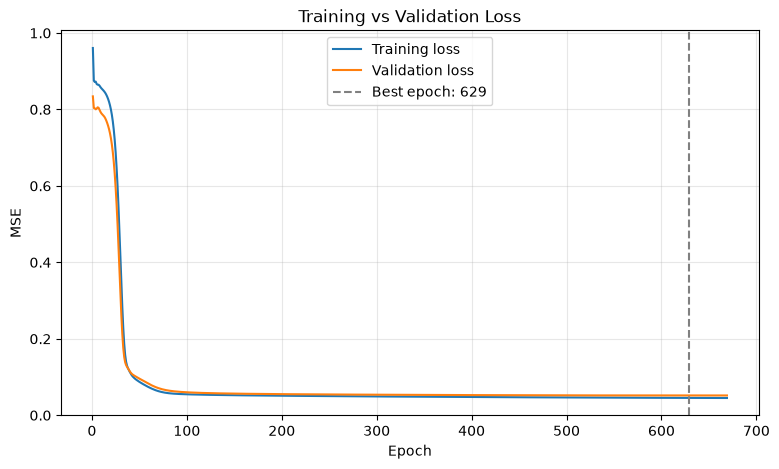

Best epoch: 629
Minimum validation loss: 0.05182
Final validation loss: 0.05185


In [44]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = np.arange(1, len(train_loss) + 1)
best_epoch = np.argmin(val_loss) + 1

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")

plt.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Best epoch: {best_epoch}")
print(f"Minimum validation loss: {min(val_loss):.5f}")
print(f"Final validation loss: {val_loss[-1]:.5f}")

Here you have val loss vs training loss. As you can see its good convergence which indicates good fitting. They go together and flat out together at a pretty low level. If it was overfitted the val loss would increase, and if it was underfitting it would go that low.
However, the final values are probably not a good way to judge the model alone. If you just look at the last value you could be seeing a very low training loss which looks like a success, but the best epoch might be hundreds ago. But therefore we have early stop with restore best weights. Therefore we dont use the final value, but the best one. this also stops overfitting. 

### ❓ Which optimization techniques did you try? What worked and what did not?
I experimented with several optimization techinques to improve both neural networks. 
For classification, Adam performed well with a learning rate of .003 giving the lowest average validation loss among the tested values. However its performance was very similar to that of .001. Using tanh activation in the hidden layers allowed the network to leaern the XOR like decision boundary effectively, achiecing up to 94% validation accuracy. 

For regression, the initial ReLU based network captured the general shape of the underlying function, but struggled to reach the required accuracy. Switching to GELU activation combined with standardization of features and targets allowed me to push the RMSE within the required values. 

Early stopping was used throughout every test to limit unnecessary training and to restore weights corresponding to lowest val loss. I also evaluated loss accross multiple seed to reduce the randomness.

Overall I found that carefully selecting learning rate and activation function was particulary important, and model complexity wasnt necessarily needed to improce the model. 


### ❓ How did you ensure reproducibility?
I used fixed random seeds for model initialization and data splitting. This allowed me to repeat experiments under consistent conditions. 

I evaluated different hyperparameter configs across multiple seeds, comparing the mean and standard deviation of validation performance. This reduced the risk of selecting a model based on a lucky seed. 

I also kept the training and val sets consistent across hyperparameter tuning, and I used the same evaluation metrcis across experiments. 

# 🤖 Problem 2: Unsupervised Learning

### ❗️ The problem

1. Identify the number of clusters in the dataset.
2. Assign a cluster label to every row and validate on [Kaggle](https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86) until you reach at least **99%** clustering accuracy.
3. Visualize the clusters in 2D, and identify what each cluster is.
4. Some rows do not belong with the others. Find those rows and show what they are.

### 💡 Hints

1. **Large Dataset**: The data set **unsupervised_data.csv** is huge! There are many features, dimensionality reduction can help.
2. **Unsupervised Learning**: No target labels are provided, patterns must come from the features alone.
3. **Data Obfuscation**: The data has a structured format. Try to find the meaning and correct ordering of the features.

### 📚 Resources

- [Clustering in scikit-learn](https://scikit-learn.org/stable/modules/clustering.html) (KMeans, DBSCAN, …)
- [Manifold learning](https://scikit-learn.org/stable/modules/manifold.html) (PCA, t-SNE, …)
- Feel free to use any other methods you find in the scikit-learn documentation!
- Kaggle competition (50 submissions per day)

### 📋 Formal requirements

1. Identify the number of clusters in the dataset.
2. Reach at least **99%** clustering accuracy on Kaggle.
3. Visualize the clusters in 2D.
4. Identify what each cluster corresponds to.
5. Some rows do not belong here, perform anomaly detection and find those samples.
6. **Discussion**
   - Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.
   - Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.
   - What is the hidden modality? How does this impact dimensionality reduction and clustering?
   - List the facilities in Trondheim and how you identified them.
   - How did you detect the rows that do not belong, and what were they?

## 🏆 Kaggle

Kaggle is a popular platform for machine learning competitions. It allows hosts to share datasets while keeping the labels hidden from the participants. The clustering labels are not available locally. Use **Kaggle** to check your cluster assignments.

- Invitation: https://www.kaggle.com/t/bce19782f3e4447e9bc9de37f36cee86
- Upload a CSV with columns `ID` and `cluster` (integer cluster ids) to check your score.
- Also include the final **submission.csv** in your Canvas delivery, together with the notebook.


In [8]:
# Why did we skip the first row? Maybe it's useful metadata for later...
data = pd.read_csv("unsupervised_data.csv", skiprows=1, header=None)
data = data.reset_index(names="ID")
data

,ID,0,1,2,3,4,5,6,7,8,...,16374,16375,16376,16377,16378,16379,16380,16381,16382,16383
0,0,0.314365,0.646305,0.323849,0.238492,0.655790,0.646305,0.646305,0.409205,0.646305,...,0.646305,0.646305,0.655790,0.238492,0.646305,0.674758,0.646305,0.238492,0.655790,0.646305
1,1,0.587628,0.494976,0.559832,-0.246237,0.513506,0.550567,0.522772,0.596893,0.606158,...,0.587628,0.550567,0.587628,0.587628,0.550567,0.587628,0.550567,0.596893,0.494976,0.587628
2,2,0.590203,0.367673,0.367673,0.367673,0.367673,0.590203,0.367673,0.590203,0.590203,...,0.590203,0.367673,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.590203,0.476556
3,3,0.589296,0.589296,0.579825,0.551415,0.579825,0.579825,0.608236,0.579825,0.646118,...,0.532474,0.523003,0.589296,0.589296,0.551415,0.134721,0.475652,0.589296,0.570355,0.551415
4,4,0.660095,0.470676,0.190366,0.672806,0.470761,0.672766,0.672652,0.666151,0.672987,...,0.432001,0.672222,0.190568,0.217329,0.633684,0.673294,0.587914,0.671023,0.207578,0.470765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3995,0.340739,0.340739,0.340739,0.681823,0.340739,0.340739,0.340739,0.672083,0.340739,...,0.340739,0.662355,0.340739,0.759779,0.331011,0.759779,0.340739,0.691563,0.340734,0.720789
3996,3996,0.384257,0.384257,0.675221,0.384257,0.384257,0.675221,0.384257,0.675221,0.675221,...,0.675221,0.384257,0.675221,0.675221,0.675221,0.384257,0.384257,0.384257,0.675221,0.675221
3997,3997,0.641837,0.651135,0.251329,0.251329,0.651135,0.651135,0.251329,0.651135,0.651135,...,0.251329,0.251329,0.651135,0.251329,0.409392,0.604646,0.651135,0.651135,0.660433,0.251329
3998,3998,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,-0.212897,0.555533,...,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533,0.555533


In [9]:
# Probably too many columns for naive clustering on raw pixels
data.info(max_cols=5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Columns: 16385 entries, ID to 16383
dtypes: float64(16384), int64(1)
memory usage: 500.0 MB


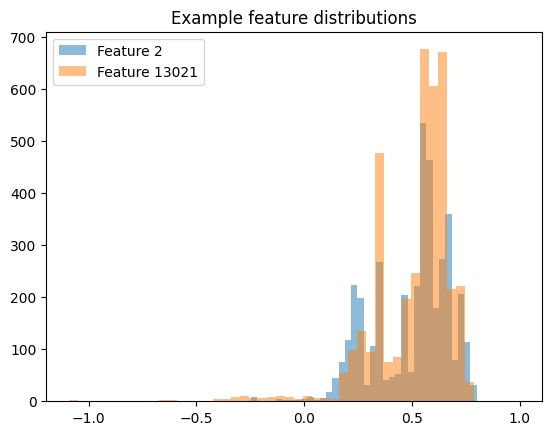

In [10]:
features = data.drop(columns="ID")
plt.hist(features.iloc[:, 2], bins=50, alpha=0.5, label="Feature 2")
plt.hist(features.iloc[:, 13021], bins=50, alpha=0.5, label="Feature 13021")
plt.legend()
plt.title("Example feature distributions")
plt.show()

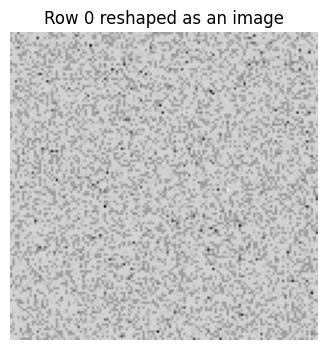

In [11]:
# 16384 = 128 × 128. Coincidence? This may be a flattened grayscale image...
row = data.iloc[0, 1:].astype(float).to_numpy()
image = row.reshape(128, 128).T
image = (image - image.min()) / (image.max() - image.min() + 1e-8)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Row 0 reshaped as an image")
plt.axis("off")
plt.show()

# If it really is an image, then pixels look scrambled.
# The true order may be encoded elsewhere. Maybe the dropped row contained important information?

In [12]:
# Kaggle submission format. The cluster ids here are just placeholders and do not hint at k.
sample_submission = pd.read_csv("sample_submission.csv")
sample_submission.head()

,ID,cluster
0,0,2
1,1,6
2,2,3
3,3,3
4,4,8


In [13]:
# ====================================
# YOUR CODE GOES HERE
# ====================================

### ❓ Which dimensionality reduction methods helped you choose *k*? Compare PCA and t-SNE in 2D.


### ❓ Which clustering algorithm and hyperparameters did you use? Compare KMeans and DBSCAN.


### ❓ What is the hidden modality? How does this impact dimensionality reduction and clustering?


### ❓ List the facilities in Trondheim and how you identified them.

### ❓ How did you detect the rows that do not belong, and what were they?


---

## Note: Clustering accuracy metric

Kaggle scores clustering with **label-invariant** accuracy: only the grouping matters, not the numeric ids.

If true labels are `[0, 0, 0, 1, 1, 1]` and you predict `[1, 1, 1, 0, 0, 0]`, accuracy is **1.0** because clusters match after renaming.

### How it is computed

1. Build a contingency matrix between true and predicted labels.
2. Find the best label matching (Hungarian algorithm / `linear_sum_assignment`).
3. Accuracy = matched points / total points.

---

In [14]:
import scipy.optimize
import sklearn.metrics


def calculate_clustering_accuracy(true_labels: np.ndarray, cluster_labels: np.ndarray) -> float:
    """Clustering accuracy with optimal permutation of cluster ids."""
    if true_labels.size != cluster_labels.size:
        raise ValueError("true_labels and cluster_labels must have the same length.")

    contingency = sklearn.metrics.cluster.contingency_matrix(true_labels, cluster_labels)
    row_ind, col_ind = scipy.optimize.linear_sum_assignment(-contingency)
    correct = contingency[row_ind, col_ind].sum()
    return correct / true_labels.size

In [15]:
true_labels = np.array([0, 1, 2, 0, 1, 2])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(1.0)

In [16]:
# Single cluster in ground truth: accuracy is share of majority predicted cluster
true_labels = np.array([0, 0, 0, 0, 0, 0])
cluster_labels = np.array([1, 2, 0, 1, 2, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.3333333333333333)

In [17]:
# Wrong number of groups: low accuracy
true_labels = np.array([1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0])
calculate_clustering_accuracy(true_labels, cluster_labels)

np.float64(0.5)